# AI vs Real Image Classification — Local CNN Project

이 노트북은 Kaggle 예제의 구조를 영훈님의 로컬 데이터셋 경로(`/Users/goyeonghun/Downloads`)와 강의 자료 수준의 CNN 개념에 맞게 단순화한 버전입니다.

핵심 흐름:

1. 로컬 다운로드 폴더의 REAL / FAKE 이미지 경로 수집  
2. `train_test_split`으로 train / validation / test 분리  
3. `tf.data` 파이프라인으로 이미지 로드  
4. 기본 CNN 모델 학습  
5. Accuracy, Loss, Confusion Matrix로 평가


## 1. 필요한 패키지 설치

이미 설치되어 있으면 다시 설치하지 않아도 됩니다. 오류가 나는 패키지만 설치해도 됩니다.

In [53]:
import sys

# 현재 Jupyter 커널에 직접 설치
!{sys.executable} -m pip install -q pillow pandas numpy matplotlib scikit-learn tensorflow

print("Package check complete.")


[notice] A new release of pip is available: 26.0.1 -> 26.1.1
[notice] To update, run: pip install --upgrade pip
Package check complete.


## 2. 라이브러리 불러오기 및 GPU 확인

In [54]:
from pathlib import Path
from PIL import Image, ImageFile
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_class_weight

ImageFile.LOAD_TRUNCATED_IMAGES = True

SEED = 42
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
EPOCHS = 10

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU Devices:", tf.config.list_physical_devices("GPU"))

# Mac M-series + tensorflow-metal 환경이면 GPU가 표시될 수 있음
for gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except Exception:
        pass

TensorFlow: 2.16.2
GPU Devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. 로컬 데이터셋 경로 설정

아래 경로는 현재 Mac의 `Downloads` 폴더 구조에 맞춘 것입니다.

In [55]:
from pathlib import Path
import pandas as pd

DOWNLOADS = Path("/Users/goyeonghun/Downloads")

VALID_EXTS = {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".tiff"}

DATASETS = {
    "CIFAKE": {
        "real": [
            DOWNLOADS / "CIFAKE" / "train" / "REAL",
            DOWNLOADS / "CIFAKE" / "test" / "REAL",
        ],
        "fake": [
            DOWNLOADS / "CIFAKE" / "train" / "FAKE",
            DOWNLOADS / "CIFAKE" / "test" / "FAKE",
        ],
    },

    "Data": {
        "real": [
            DOWNLOADS / "Data" / "REAL",
        ],
        "fake": [
            DOWNLOADS / "Data" / "FAKE",
        ],
    },

    "AI vs Real Images Dataset": {
        "real": [
            DOWNLOADS / "AI vs Real Images Dataset" / "real_dataset",
        ],
        "fake": [
            DOWNLOADS / "AI vs Real Images Dataset" / "Ai_generated_dataset",
        ],
    },

    "AI Generated Images vs Real Images": {
        "real": [
            DOWNLOADS / "AI Generated Images vs Real Images" / "RealArt" / "RealArt",
        ],
        "fake": [
            DOWNLOADS / "AI Generated Images vs Real Images" / "AiArtData" / "AiArtData",
        ],
    },

    "AI-face-detection-Dataset": {
        "real": [
            DOWNLOADS / "AI-face-detection-Dataset" / "real",
        ],
        "fake": [
            DOWNLOADS / "AI-face-detection-Dataset" / "AI",
        ],
    },

    "datasetfull": {
        "real": [
            DOWNLOADS / "datasetfull" / "Real",
        ],
        "fake": [
            DOWNLOADS / "datasetfull" / "AI",
        ],
    },
}


def collect_images_from_dirs(dirs, label):
    rows = []

    for d in dirs:
        if not d.exists() or not d.is_dir():
            continue

        for p in d.rglob("*"):
            if p.suffix.lower() in VALID_EXTS:
                rows.append({
                    "filepath": str(p),
                    "label": label,
                    "source_dir": str(d)
                })

    return rows


def make_df_for_dataset(dataset_name):
    real_dirs = DATASETS[dataset_name]["real"]
    fake_dirs = DATASETS[dataset_name]["fake"]

    real_rows = collect_images_from_dirs(real_dirs, "real")
    fake_rows = collect_images_from_dirs(fake_dirs, "fake")

    df = pd.DataFrame(real_rows + fake_rows)

    if len(df) == 0:
        print(f"[오류] {dataset_name}: 이미지가 없습니다.")
        return df

    print("=" * 60)
    print("Dataset:", dataset_name)
    print("=" * 60)
    print(df["label"].value_counts())
    print("\n사용된 폴더:")
    for d in sorted(df["source_dir"].unique()):
        print(d)

    return df

In [56]:
def make_df_for_ai_vs_human():
    base_dir = DOWNLOADS / "AI vs Human-Generated Images"

    train_csv = pd.read_csv(base_dir / "train.csv")

    df = pd.DataFrame()
    df["filepath"] = train_csv["file_name"].apply(lambda x: str(base_dir / x))

    # 0 = real, 1 = fake
    df["label"] = train_csv["label"].map({
        0: "real",
        1: "fake"
    })

    df["source_dir"] = str(base_dir / "train_data")

    print("=" * 60)
    print("Dataset: AI vs Human-Generated Images")
    print("=" * 60)
    print(df["label"].value_counts())

    return df

## 4. 이미지 경로 수집 및 DataFrame 생성

In [57]:
def collect_images(dirs, label):
    rows = []
    for d in dirs:
        if not d.exists():
            continue

        for p in d.rglob("*"):
            if p.is_file() and p.suffix.lower() in VALID_EXTS:
                rows.append({
                    "filepath": str(p),
                    "label": label
                })

    return rows

real_rows = collect_images(real_dirs, 0)  # 0 = real
fake_rows = collect_images(fake_dirs, 1)  # 1 = fake

df = pd.DataFrame(real_rows + fake_rows)
df = df.drop_duplicates(subset=["filepath"]).reset_index(drop=True)

print("Total images:", len(df))
print(df["label"].value_counts().rename(index={0: "real", 1: "fake"}))
display(df.head())

if len(df) == 0:
    raise ValueError("이미지를 찾지 못했습니다. real_dirs / fake_dirs 경로를 다시 확인하세요.")

Total images: 155743
label
real    79624
fake    76119
Name: count, dtype: int64


,filepath,label
0,/Users/goyeonghun/Downloads/CIFAKE/train/REAL/...,0
1,/Users/goyeonghun/Downloads/CIFAKE/train/REAL/...,0
2,/Users/goyeonghun/Downloads/CIFAKE/train/REAL/...,0
3,/Users/goyeonghun/Downloads/CIFAKE/train/REAL/...,0
4,/Users/goyeonghun/Downloads/CIFAKE/train/REAL/...,0


## 5. Train / Validation / Test 분리

비율은 80 / 10 / 10입니다.

In [58]:
X = df["filepath"].values
y = df["label"].values.astype("int32")

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

# class_weights_values = compute_class_weight(
#     class_weight="balanced",
#     classes=np.array([0, 1]),
#     y=y_train
# )

# class_weights = {
#     0: float(class_weights_values[0]),
#     1: float(class_weights_values[1])
# }

# print("Class weights:", class_weights)

Train: 124594
Validation: 15574
Test: 15575


## 6. 이미지 로드 함수와 tf.data 파이프라인

`PIL`을 사용하므로 `.jpg`, `.png`, `.webp`, `.bmp`를 모두 처리할 수 있습니다.

In [59]:
import warnings
from PIL import Image, ImageFile
import numpy as np
import tensorflow as tf

ImageFile.LOAD_TRUNCATED_IMAGES = True

warnings.filterwarnings(
    "ignore",
    message="Palette images with Transparency expressed in bytes should be converted to RGBA images"
)

AUTOTUNE = tf.data.AUTOTUNE

def load_image_with_pil(path):
    path = path.numpy().decode("utf-8")

    with Image.open(path) as img:
        img = img.convert("RGB")
        img = img.resize((IMG_SIZE[1], IMG_SIZE[0]))
        img = np.asarray(img, dtype=np.float32) / 255.0

    return img

def load_image(path, label):
    img = tf.py_function(load_image_with_pil, [path], tf.float32)
    img.set_shape((IMG_SIZE[0], IMG_SIZE[1], 3))

    label = tf.cast(label, tf.float32)

    return img, label

def augment_image(img, label):
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_brightness(img, max_delta=0.1)
    img = tf.image.random_contrast(img, lower=0.9, upper=1.1)
    img = tf.clip_by_value(img, 0.0, 1.0)

    return img, label

def make_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)

    if training:
        ds = ds.shuffle(buffer_size=min(len(paths), 3000), seed=SEED)
        ds = ds.map(augment_image, num_parallel_calls=AUTOTUNE)

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds

train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val, training=False)
test_ds = make_dataset(X_test, y_test, training=False)

print("train_ds:", train_ds)
print("val_ds:", val_ds)
print("test_ds:", test_ds)

train_ds: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.float32, name=None))>
val_ds: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.float32, name=None))>
test_ds: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.float32, name=None))>


## 7. 샘플 이미지 확인

2026-06-01 02:17:12.850246: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


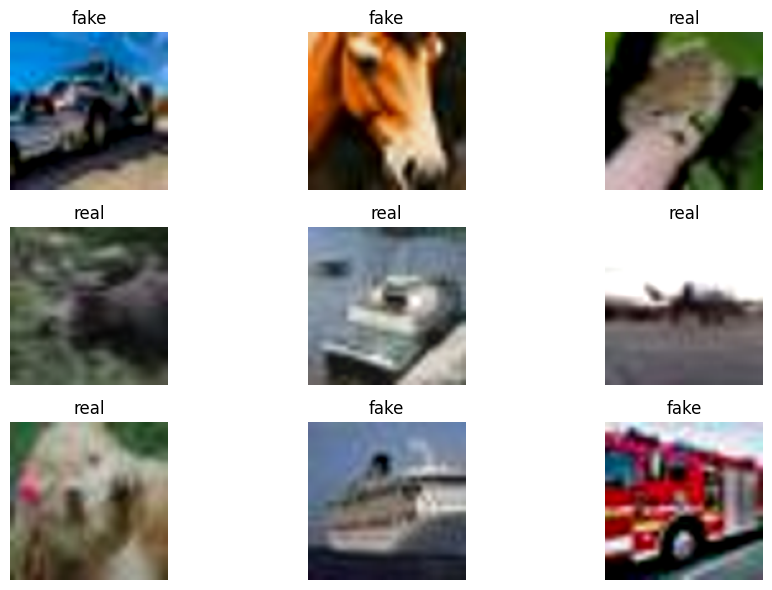

In [60]:
class_names = {0: "real", 1: "fake"}

plt.figure(figsize=(10, 6))

for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy())
        plt.title(class_names[int(labels[i].numpy())])
        plt.axis("off")

plt.tight_layout()
plt.show()

## 8. CNN 모델 구성

강의 자료의 기본 CNN 흐름인 `Conv2D → MaxPooling2D → Flatten → Dense` 구조를 사용합니다.

In [61]:
cnn_model = keras.Sequential([
    layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(1, activation="sigmoid")
])

cnn_model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)              │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,287,809 (16.36 MB)

 Trainable params: 4,287,809 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

## 9. 모델 컴파일 + 모델 학습

In [62]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    "best_ai_real_cnn.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max"
)

cnn_model.compile(
    optimizer=Adam(learning_rate=0.00005),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

cnn_history = cnn_model.fit(
    train_ds,
    epochs=EPOCHS,
    validation_data=val_ds,
    callbacks=[early_stop, checkpoint]
)

Epoch 1/10
3894/3894 ━━━━━━━━━━━━━━━━━━━━ 262s 66ms/step - accuracy: 0.7514 - loss: 0.5155 - val_accuracy: 0.7988 - val_loss: 0.4384
Epoch 2/10
3894/3894 ━━━━━━━━━━━━━━━━━━━━ 278s 71ms/step - accuracy: 0.7356 - loss: 1.1290 - val_accuracy: 0.7955 - val_loss: 0.7004
Epoch 3/10
3894/3894 ━━━━━━━━━━━━━━━━━━━━ 302s 77ms/step - accuracy: 0.6910 - loss: 2.9816 - val_accuracy: 0.7800 - val_loss: 1.5214
Epoch 4/10
1635/3894 ━━━━━━━━━━━━━━━━━━━━ 2:35 69ms/step - accuracy: 0.6667 - loss: 5.2261

KeyboardInterrupt: 

## 11. 학습 결과 시각화

In [ ]:
history = cnn_history.history

plt.figure(figsize=(8, 5))
plt.plot(history["accuracy"], label="train accuracy")
plt.plot(history["val_accuracy"], label="validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history["loss"], label="train loss")
plt.plot(history["val_loss"], label="validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

## 12. 테스트 데이터 평가

In [ ]:
test_loss, test_acc = cnn_model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_acc)

## 13. Confusion Matrix와 Classification Report

In [ ]:
y_prob = cnn_model.predict(test_ds).reshape(-1)
y_pred = (y_prob >= 0.5).astype(int)

print(classification_report(
    y_test,
    y_pred,
    target_names=["real", "fake"]
))

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["real", "fake"]
)

disp.plot()
plt.title("Confusion Matrix")
plt.show()

## 14. 테스트 이미지 예측 예시

In [ ]:
plt.figure(figsize=(12, 8))

for images, labels in test_ds.take(1):
    probs = cnn_model.predict(images).reshape(-1)
    preds = (probs >= 0.5).astype(int)

    for i in range(min(12, len(images))):
        ax = plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy())
        true_label = class_names[int(labels[i].numpy())]
        pred_label = class_names[int(preds[i])]
        confidence = probs[i] if preds[i] == 1 else 1 - probs[i]
        plt.title(f"T:{true_label} / P:{pred_label}\\nconf:{confidence:.2f}")
        plt.axis("off")

plt.tight_layout()
plt.show()

## 15. 모델 저장

In [ ]:
cnn_model.save("final_ai_real_cnn.keras")
print("Model saved: final_ai_real_cnn.keras")